In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
display(df.head())
print(df.info())
display(df.describe(include="all").T)

Saving seasonal_agriculture_performance_dataset.csv to seasonal_agriculture_performance_dataset (1).csv
Dataset shape: (4000, 28)


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,...,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,...,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,...,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,...,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,...,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   object 
 1   State                          4000 non-null   object 
 2   District                       4000 non-null   object 
 3   Crop                           4000 non-null   object 
 4   Season                         4000 non-null   object 
 5   Farm_Area_Hectares             4000 non-null   float64
 6   Rainfall_mm                    3952 non-null   float64
 7   Avg_Temperature_C              4000 non-null   float64
 8   Humidity_pct                   4000 non-null   float64
 9   Sunlight_Hours_Day             4000 non-null   float64
 10  Soil_pH                        4000 non-null   float64
 11  Soil_Moisture_pct              3960 non-null   float64
 12  Nitrogen_kg_ha                 4000 non-null   f

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Farm_ID,4000,4000,SF13984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,4000,8,Andhra Pradesh,529,NaN,NaN,NaN,NaN,NaN,NaN,NaN
District,4000,10,Ludhiana,427,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop,4000,8,Rice,690,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Season,4000,3,Kharif,1779,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Farm_Area_Hectares,4000.0,NaN,NaN,NaN,7.888265,4.223764,0.5,4.26,7.895,11.65,15.0
Rainfall_mm,3952.0,NaN,NaN,NaN,601.152657,288.925025,80.0,370.2,582.0,834.95,1395.2
Avg_Temperature_C,4000.0,NaN,NaN,NaN,26.8189,3.81818,16.2,23.9,26.9,29.6,39.7
Humidity_pct,4000.0,NaN,NaN,NaN,63.2105,11.960834,25.0,54.775,63.0,71.9,95.0
Sunlight_Hours_Day,4000.0,NaN,NaN,NaN,7.32305,1.121186,3.5,6.6,7.3,8.1,11.0


In [2]:
# Column names and data types
print(df.dtypes)

# Missing values
print(df.isnull().sum().sort_values(ascending=False))

# Duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Unique values in categorical columns
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).head(15))

Farm_ID                           object
State                             object
District                          object
Crop                              object
Season                            object
Farm_Area_Hectares               float64
Rainfall_mm                      float64
Avg_Temperature_C                float64
Humidity_pct                     float64
Sunlight_Hours_Day               float64
Soil_pH                          float64
Soil_Moisture_pct                float64
Nitrogen_kg_ha                   float64
Phosphorus_kg_ha                 float64
Potassium_kg_ha                  float64
Irrigation_Method                 object
Fertilizer_kg_ha                 float64
Pesticide_Litre_ha               float64
Seed_Quality_Score               float64
Yield_Tonnes_Ha                  float64
Production_Tonnes                float64
Market_Price_INR_Tonne             int64
Total_Cost_INR                     int64
Revenue_INR                        int64
Profit_INR      

In [3]:
# Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Remove exact duplicate records
df = df.drop_duplicates().copy()

# Standardize categorical text
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Standardize common crop-name variations
crop_col = next(
    (c for c in df.columns if c in ["crop", "crop_type", "crop_name"]),
    None
)

if crop_col:
    df[crop_col] = df[crop_col].replace({
        "rice ": "Rice",
        "RICE": "Rice",
        "wheat": "Wheat",
        "WHEAT": "Wheat"
    })

# Fill missing numeric values with medians
numeric_cols = df.select_dtypes(include=np.number).columns
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with the mode
for col in df.select_dtypes(include="object").columns:
    if df[col].isnull().any() and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Shape after cleaning:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

Shape after cleaning: (4000, 28)
Remaining missing values: 0


count    4000.000000
mean        5.242350
std        13.311549
min         0.300000
25%         1.050000
50%         1.740000
75%         2.830000
max       101.440000
Name: yield_tonnes_ha, dtype: float64
Potential yield outliers: 302


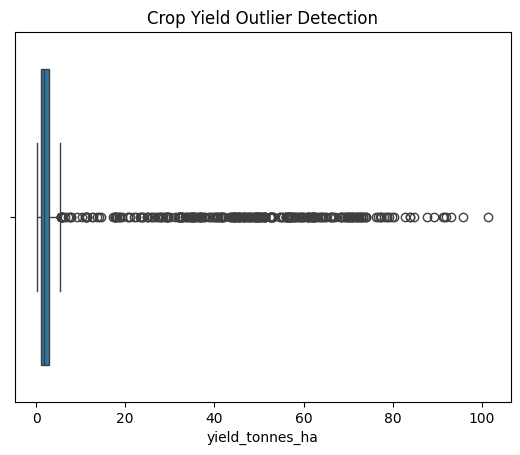

In [4]:
yield_col = next(
    (c for c in df.columns
     if c in ["yield_tonnes_ha", "yield", "crop_yield", "yield_kg_ha"]),
    None
)

if yield_col:
    print(df[yield_col].describe())

    Q1 = df[yield_col].quantile(0.25)
    Q3 = df[yield_col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[yield_col] < lower) |
        (df[yield_col] > upper)
    ]

    print("Potential yield outliers:", len(outliers))

    sns.boxplot(x=df[yield_col])
    plt.title("Crop Yield Outlier Detection")
    plt.show()
else:
    print("Check the yield column name:", df.columns.tolist())

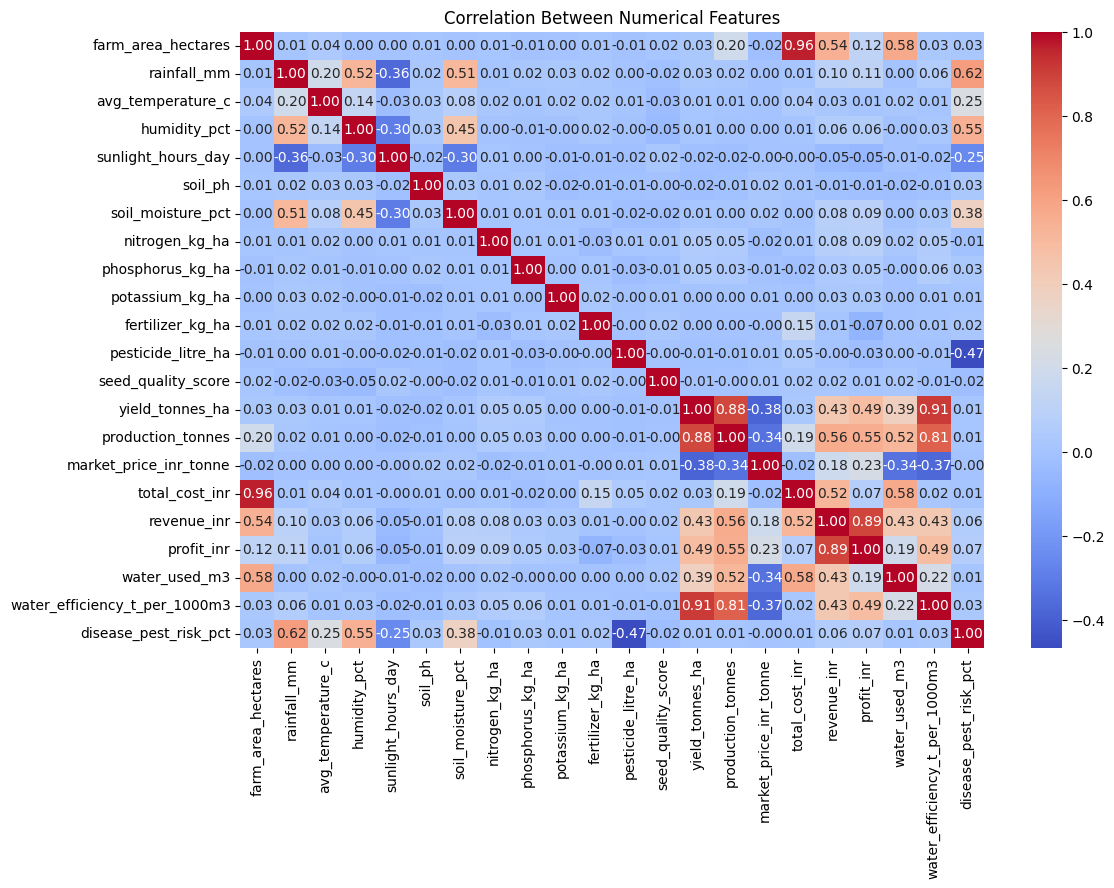

In [5]:
# Correlation heatmap
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Numerical Features")
plt.show()

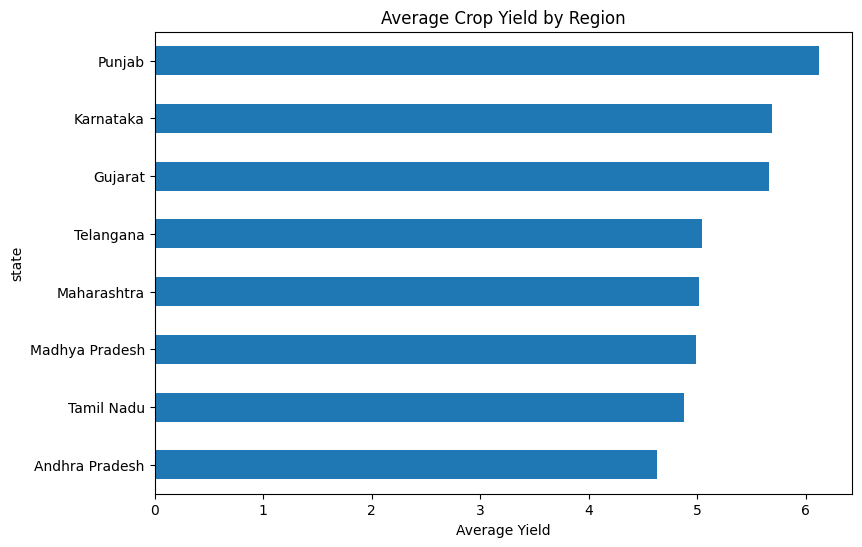

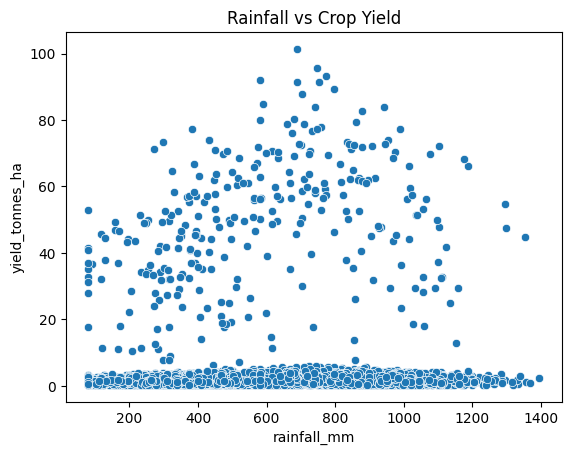

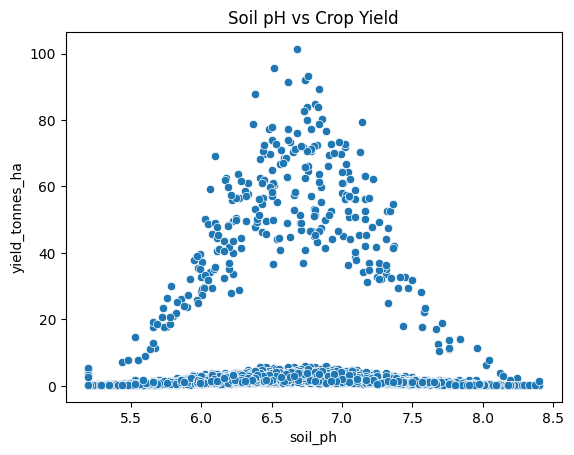

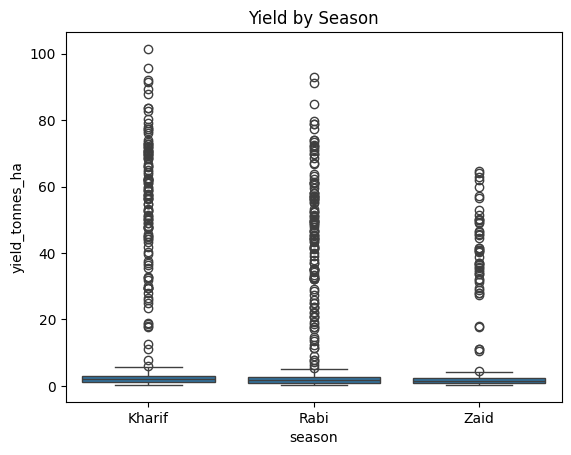

In [6]:
def find_col(candidates):
    return next((c for c in candidates if c in df.columns), None)

region = find_col(["region", "state", "district"])
rain = find_col(["rainfall_mm", "rainfall", "annual_rainfall", "rain"])
soil = find_col(["soil_ph", "ph"])
irrigation = find_col(["irrigation", "irrigation_type"])
season = find_col(["season", "sowing_period"])
yield_col = find_col(["yield_tonnes_ha", "yield", "crop_yield"])

# Yield by region
if region and yield_col:
    df.groupby(region)[yield_col].mean().sort_values().plot(
        kind="barh", figsize=(9, 6)
    )
    plt.title("Average Crop Yield by Region")
    plt.xlabel("Average Yield")
    plt.show()

# Rainfall vs yield
if rain and yield_col:
    sns.scatterplot(data=df, x=rain, y=yield_col)
    plt.title("Rainfall vs Crop Yield")
    plt.show()

# Soil pH vs yield
if soil and yield_col:
    sns.scatterplot(data=df, x=soil, y=yield_col)
    plt.title("Soil pH vs Crop Yield")
    plt.show()

# Irrigation comparison
if irrigation and yield_col:
    sns.boxplot(data=df, x=irrigation, y=yield_col)
    plt.xticks(rotation=30)
    plt.title("Yield by Irrigation Method")
    plt.show()

# Season comparison
if season and yield_col:
    sns.boxplot(data=df, x=season, y=yield_col)
    plt.title("Yield by Season")
    plt.show()

In [7]:
# Yield per hectare, if production and farm area are available
area_col = find_col(["farm_area_hectares", "area", "farm_area"])
production_col = find_col(["production_tonnes", "production"])

if area_col and production_col:
    df["calculated_yield_per_hectare"] = (
        df[production_col] / df[area_col].replace(0, np.nan)
    )

# Rainfall categories
if rain:
    df["rainfall_category"] = pd.cut(
        df[rain],
        bins=[-np.inf, 500, 1000, 1500, np.inf],
        labels=["Low", "Moderate", "High", "Very High"]
    )

# Seasonal feature: already available in the dataset
if season:
    print("Season categories:", df[season].unique())

# Encode categorical features
categorical_cols = df.select_dtypes(
    include="object"
).columns.tolist()

encoded_df = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Original features:", df.shape[1])
print("Encoded features:", encoded_df.shape[1])

Season categories: ['Kharif' 'Rabi' 'Zaid']
Original features: 30
Encoded features: 4051


In [8]:
if yield_col:
    correlations = (
        df.select_dtypes(include=np.number)
        .corr()[yield_col]
        .drop(yield_col)
        .sort_values(key=abs, ascending=False)
    )

    print("Features ranked by absolute correlation:")
    display(correlations.to_frame("correlation"))

    correlations.to_csv("feature_correlations.csv")

Features ranked by absolute correlation:


,correlation
calculated_yield_per_hectare,0.997218
water_efficiency_t_per_1000m3,0.912568
production_tonnes,0.882813
profit_inr,0.488466
revenue_inr,0.432152
water_used_m3,0.386294
market_price_inr_tonne,-0.382607
nitrogen_kg_ha,0.053149
phosphorus_kg_ha,0.047941
rainfall_mm,0.030951


In [9]:
df.to_csv("crop_yield_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")

files.download("crop_yield_cleaned.csv")

Cleaned dataset saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>